# ДЗ 3 (Пащенко Дмитрий)

Всё на ноуте, "ВМ" `vm1` - это он. Файлы в `hw3/`.

In [1]:
%%bash
cat /etc/os-release | head -2
docker --version
docker compose version
free -h | head -2

NAME="Arch Linux"
PRETTY_NAME="Arch Linux"
Docker version 29.9.0, build f415da838b
Docker Compose version 5.6.0
               total        used        free      shared  buff/cache   available
Mem:            14Gi       9.4Gi       947Mi       498Mi       5.4Gi       5.4Gi


## Задание 1. Мониторинг ВМ
compose из задания, в `prometheus.yml` дописал job `node`:

In [2]:
%%bash
cd hw3/monitoring
cat compose.yaml
echo "=================="
cat prometheus/prometheus.yml

services:
  prometheus:
    image: prom/prometheus:v3.5.0
    command:
      - --config.file=/etc/prometheus/prometheus.yml
      - --storage.tsdb.path=/prometheus
      - --storage.tsdb.retention.time=15d
    volumes:
      - ./prometheus:/etc/prometheus:ro
      - prometheus-data:/prometheus
    ports:
      - 127.0.0.1:9090:9090
    extra_hosts:
      - host.docker.internal:host-gateway   # адрес хоста — для node-exporter в сети хоста
    restart: unless-stopped

  node-exporter:
    image: prom/node-exporter:v1.9.1
    command: [--path.rootfs=/host]
    pid: host
    network_mode: host          # видеть реальные сетевые интерфейсы хоста, слушает :9100
    volumes:
      - /:/host:ro              # на обычном Linux можно ro,rslave; в WSL rslave не работает
    restart: unless-stopped

  grafana:
    image: grafana/grafana:12.1.0
    volumes:
      - grafana-data:/var/lib/grafana
    ports:
      - 127.0.0.1:3000:3000
    restart: unless-stopped

volumes:
  prometheus-data:
  grafana

In [3]:
%%bash
cd hw3/monitoring
docker compose up -d 2>&1
sleep 5
docker compose ps

 Container monitoring-node-exporter-1 Creating 
 Volume monitoring_prometheus-data Creating 
 Volume monitoring_prometheus-data Creating 
 Network monitoring_default Creating 
 Network monitoring_default Creating 
 Volume monitoring_grafana-data Creating 
 Volume monitoring_grafana-data Creating 
 Volume monitoring_prometheus-data Created 
 Volume monitoring_prometheus-data Created 
 Volume monitoring_grafana-data Created 
 Volume monitoring_grafana-data Created 
 Network monitoring_default Created 
 Network monitoring_default Created 
 Container monitoring-prometheus-1 Creating 
 Container monitoring-grafana-1 Creating 
 Container monitoring-node-exporter-1 Created 
 Container monitoring-grafana-1 Created 
 Container monitoring-prometheus-1 Created 
 Container monitoring-grafana-1 Starting 
 Container monitoring-node-exporter-1 Starting 
 Container monitoring-prometheus-1 Starting 
 Container monitoring-grafana-1 Started 
 Container monitoring-node-exporter-1 Started 
 Container monit

### Node Exporter

In [4]:
%%bash
curl -s localhost:9100/metrics | grep '^node_' | head -15
echo ...
echo "всего строк с метриками node_*: $(curl -s localhost:9100/metrics | grep -c '^node_')"

node_arp_entries{device="br-5c2311b4b871"} 1
node_arp_entries{device="br-87e2ff52c1dc"} 1
node_arp_entries{device="docker0"} 5
node_arp_entries{device="wlp1s0"} 1
node_boot_time_seconds 1.791314005e+09
node_context_switches_total 4.907049184e+09
node_cooling_device_cur_state{name="0",type="Processor"} 0
node_cooling_device_cur_state{name="1",type="Processor"} 0
node_cooling_device_cur_state{name="10",type="Processor"} 0
node_cooling_device_cur_state{name="11",type="Processor"} 0
node_cooling_device_cur_state{name="12",type="Processor"} 0
node_cooling_device_cur_state{name="13",type="Processor"} 0
node_cooling_device_cur_state{name="14",type="Processor"} 0
node_cooling_device_cur_state{name="15",type="Processor"} 0
node_cooling_device_cur_state{name="2",type="Processor"} 0
...
всего строк с метриками node_*: 1293


### Цель в Prometheus
смотрю цели через API (то же что /targets):

In [5]:
%%bash
sleep 40
curl -s localhost:9090/api/v1/targets | jq -r '.data.activeTargets[] | "\(.labels.job)\t\(.labels.instance)\t\(.health)\t\(.lastError)"'

node	vm1	down	Get "http://host.docker.internal:9100/metrics": context deadline exceeded
prometheus	localhost:9090	up	


`node` в down. С хоста же отвечает - значит файрвол режет:

In [6]:
%%bash
sudo ufw status verbose | head -12
docker network inspect monitoring_default -f '{{range .IPAM.Config}}{{.Subnet}} gw {{.Gateway}}{{end}}'

Status: active
Logging: on (low)
Default: deny (incoming), allow (outgoing), deny (routed)
New profiles: skip

To                         Action      From
--                         ------      ----
1714:1716/tcp              ALLOW IN    Anywhere                  
1714:1716/udp              ALLOW IN    Anywhere                  
8765/tcp                   ALLOW IN    Anywhere                  
1714:1716/tcp (v6)         ALLOW IN    Anywhere (v6)             
1714:1716/udp (v6)         ALLOW IN    Anywhere (v6)             
172.19.0.0/16 gw 172.19.0.1


Открываю 9100 только для докер-сетей:

In [7]:
%%bash
sudo ufw allow from 172.16.0.0/12 to any port 9100 proto tcp comment 'prometheus (docker) -> node_exporter'
sudo ufw status | grep 9100
sleep 35
curl -s localhost:9090/api/v1/targets | jq -r '.data.activeTargets[] | "\(.labels.job)\t\(.labels.instance)\t\(.health)\t\(.lastError)"'

Rule added
9100/tcp                   ALLOW       172.16.0.0/12              # prometheus (docker) -> node_exporter
node	vm1	up	
prometheus	localhost:9090	up	


up.

### Источник данных в Grafana
Через API вместо кликов в UI, чтоб было видно в логе:

In [8]:
%%bash
curl -s -u admin:admin -H 'Content-Type: application/json' -X POST localhost:3000/api/datasources \
  -d '{"name":"Prometheus","type":"prometheus","uid":"prometheus","url":"http://prometheus:9090","access":"proxy","isDefault":true}' | jq .
# это и есть Save & test
curl -s -u admin:admin localhost:3000/api/datasources/uid/prometheus/health | jq .

{
  "datasource": {
    "id": 1,
    "uid": "prometheus",
    "orgId": 1,
    "name": "Prometheus",
    "type": "prometheus",
    "typeLogoUrl": "public/plugins/prometheus/img/prometheus_logo.svg",
    "access": "proxy",
    "url": "http://prometheus:9090",
    "user": "",
    "database": "",
    "basicAuth": false,
    "basicAuthUser": "",
    "withCredentials": false,
    "isDefault": true,
    "jsonData": {},
    "secureJsonFields": {},
    "version": 1,
    "readOnly": false,
    "apiVersion": ""
  },
  "id": 1,
  "message": "Datasource added",
  "name": "Prometheus"
}
{
  "details": {
    "application": "Prometheus",
    "features": {
      "rulerApiEnabled": false
    }
  },
  "message": "Successfully queried the Prometheus API.",
  "status": "OK"
}


### Дашборд с переменной `instance`
CPU, RAM, Диск, Сеть, везде фильтр `{instance=~"$instance"}`. JSON написал сам:

In [9]:
%%bash
cat > /tmp/hw3-dashboard.json <<'EOF'
{
  "dashboard": {
    "uid": "vm-overview",
    "title": "VM overview (Пащенко)",
    "tags": [
      "hw3",
      "node"
    ],
    "timezone": "browser",
    "refresh": "30s",
    "time": {
      "from": "now-30m",
      "to": "now"
    },
    "templating": {
      "list": [
        {
          "name": "instance",
          "label": "ВМ",
          "type": "query",
          "datasource": {
            "type": "prometheus",
            "uid": "prometheus"
          },
          "query": {
            "query": "label_values(node_uname_info, instance)",
            "refId": "vars"
          },
          "definition": "label_values(node_uname_info, instance)",
          "refresh": 2,
          "includeAll": true,
          "multi": true,
          "current": {
            "text": "All",
            "value": "$__all"
          }
        }
      ]
    },
    "panels": [
      {
        "id": 1,
        "type": "timeseries",
        "title": "CPU",
        "description": "Загрузка процессора: всё кроме idle",
        "gridPos": {
          "x": 0,
          "y": 0,
          "w": 12,
          "h": 8
        },
        "datasource": {
          "type": "prometheus",
          "uid": "prometheus"
        },
        "fieldConfig": {
          "defaults": {
            "unit": "percent",
            "min": 0,
            "max": 100
          },
          "overrides": []
        },
        "targets": [
          {
            "refId": "A",
            "legendFormat": "{{instance}}",
            "expr": "100 * (1 - avg by (instance) (rate(node_cpu_seconds_total{mode=\"idle\", instance=~\"$instance\"}[$__rate_interval])))"
          }
        ]
      },
      {
        "id": 2,
        "type": "timeseries",
        "title": "RAM",
        "description": "Занятая память (MemTotal - MemAvailable)",
        "gridPos": {
          "x": 12,
          "y": 0,
          "w": 12,
          "h": 8
        },
        "datasource": {
          "type": "prometheus",
          "uid": "prometheus"
        },
        "fieldConfig": {
          "defaults": {
            "unit": "bytes",
            "min": 0
          },
          "overrides": []
        },
        "targets": [
          {
            "refId": "A",
            "legendFormat": "{{instance}} занято",
            "expr": "node_memory_MemTotal_bytes{instance=~\"$instance\"} - node_memory_MemAvailable_bytes{instance=~\"$instance\"}"
          },
          {
            "refId": "B",
            "legendFormat": "{{instance}} всего",
            "expr": "node_memory_MemTotal_bytes{instance=~\"$instance\"}"
          }
        ]
      },
      {
        "id": 3,
        "type": "bargauge",
        "title": "Диск: свободно, %",
        "description": "Свободное место на файловых системах в % (без tmpfs/overlay)",
        "gridPos": {
          "x": 0,
          "y": 8,
          "w": 12,
          "h": 8
        },
        "datasource": {
          "type": "prometheus",
          "uid": "prometheus"
        },
        "options": {
          "orientation": "horizontal",
          "displayMode": "gradient",
          "reduceOptions": {
            "calcs": [
              "lastNotNull"
            ]
          }
        },
        "fieldConfig": {
          "defaults": {
            "unit": "percent",
            "min": 0,
            "max": 100,
            "color": {
              "mode": "thresholds"
            },
            "thresholds": {
              "mode": "absolute",
              "steps": [
                {
                  "color": "red",
                  "value": null
                },
                {
                  "color": "orange",
                  "value": 10
                },
                {
                  "color": "green",
                  "value": 20
                }
              ]
            }
          },
          "overrides": []
        },
        "targets": [
          {
            "refId": "A",
            "legendFormat": "{{instance}} {{mountpoint}}",
            "expr": "100 * node_filesystem_avail_bytes{instance=~\"$instance\", fstype!~\"tmpfs|overlay|squashfs|ramfs|nsfs|fuse.*\"} / node_filesystem_size_bytes{instance=~\"$instance\", fstype!~\"tmpfs|overlay|squashfs|ramfs|nsfs|fuse.*\"}"
          }
        ]
      },
      {
        "id": 4,
        "type": "timeseries",
        "title": "Сеть",
        "description": "Входящий и исходящий трафик (без lo и docker-интерфейсов)",
        "gridPos": {
          "x": 12,
          "y": 8,
          "w": 12,
          "h": 8
        },
        "datasource": {
          "type": "prometheus",
          "uid": "prometheus"
        },
        "fieldConfig": {
          "defaults": {
            "unit": "bps"
          },
          "overrides": []
        },
        "targets": [
          {
            "refId": "A",
            "legendFormat": "{{instance}} {{device}} in",
            "expr": "rate(node_network_receive_bytes_total{instance=~\"$instance\", device!~\"lo|veth.*|br-.*|docker.*\"}[$__rate_interval]) * 8"
          },
          {
            "refId": "B",
            "legendFormat": "{{instance}} {{device}} out",
            "expr": "rate(node_network_transmit_bytes_total{instance=~\"$instance\", device!~\"lo|veth.*|br-.*|docker.*\"}[$__rate_interval]) * 8"
          }
        ]
      }
    ]
  },
  "overwrite": true
}
EOF
curl -s -u admin:admin -H 'Content-Type: application/json' -X POST localhost:3000/api/dashboards/db -d @/tmp/hw3-dashboard.json | jq .

{
  "folderUid": "",
  "id": 1,
  "slug": "vm-overview-paschenko",
  "status": "success",
  "uid": "vm-overview",
  "url": "/d/vm-overview/vm-overview-paschenko",
  "version": 1
}


Экспорт JSON:

In [10]:
%%bash
mkdir -p hw3/monitoring/grafana
curl -s -u admin:admin localhost:3000/api/dashboards/uid/vm-overview | jq '.dashboard' > hw3/monitoring/grafana/dashboard.json
ls -la hw3/monitoring/grafana/
jq '.templating.list[] | {name, type, query: .definition, multi, includeAll}' hw3/monitoring/grafana/dashboard.json
jq -r '.panels[] | "\(.title):\n" + ([.targets[].expr] | map("   " + .) | join("\n"))' hw3/monitoring/grafana/dashboard.json

total 16
drwxr-xr-x 2 pd pd 4096 Oct 13 00:31 .
drwxr-xr-x 4 pd pd 4096 Oct 13 00:15 ..
-rw-r--r-- 1 pd pd 5089 Oct 13 00:31 dashboard.json
{
  "name": "instance",
  "type": "query",
  "query": "label_values(node_uname_info, instance)",
  "multi": true,
  "includeAll": true
}
CPU:
   100 * (1 - avg by (instance) (rate(node_cpu_seconds_total{mode="idle", instance=~"$instance"}[$__rate_interval])))
RAM:
   node_memory_MemTotal_bytes{instance=~"$instance"} - node_memory_MemAvailable_bytes{instance=~"$instance"}
   node_memory_MemTotal_bytes{instance=~"$instance"}
Диск: свободно, %:
   100 * node_filesystem_avail_bytes{instance=~"$instance", fstype!~"tmpfs|overlay|squashfs|ramfs|nsfs|fuse.*"} / node_filesystem_size_bytes{instance=~"$instance", fstype!~"tmpfs|overlay|squashfs|ramfs|nsfs|fuse.*"}
Сеть:
   rate(node_network_receive_bytes_total{instance=~"$instance", device!~"lo|veth.*|br-.*|docker.*"}[$__rate_interval]) * 8
   rate(node_network_transmit_bytes_total{instance=~"$instance", devi

## Задание 2. Dockerfile для counter-backend
Для `docker build` нужен buildx:

In [11]:
%%bash
sudo pacman -S --needed --noconfirm docker-buildx 2>&1
docker buildx version

 there is nothing to do
github.com/docker/buildx 0.38.0 0dbe87f36ed472fe36b6796c3f70b4210a731fc5


In [12]:
%%bash
cd hw3/counter-backend
ls -la
echo "===== .dockerignore"
cat .dockerignore

total 144
drwxr-xr-x 5 pd pd  4096 Oct 13 00:17 .
drwxr-xr-x 5 pd pd  4096 Oct 13 00:34 ..
drwxr-xr-x 2 pd pd  4096 Oct 13 00:15 deploy
-rw-r--r-- 1 pd pd  1567 Oct 14 23:48 Dockerfile.multistage
-rw-r--r-- 1 pd pd  1920 Oct 14 23:48 Dockerfile.nonroot
-rw-r--r-- 1 pd pd  1495 Oct 14 23:48 Dockerfile.single
-rw-r--r-- 1 pd pd   132 Oct 14 23:48 .dockerignore
-rw-r--r-- 1 pd pd   171 Oct 13 00:15 .editorconfig
-rw-r--r-- 1 pd pd   366 Oct 13 00:15 .gitignore
-rw-r--r-- 1 pd pd   438 Oct 13 00:15 Makefile
-rw-r--r-- 1 pd pd 87985 Oct 13 00:15 poetry.lock
-rw-r--r-- 1 pd pd   646 Oct 13 00:15 pyproject.toml
-rw-r--r-- 1 pd pd   692 Oct 13 00:15 README.md
drwxr-xr-x 3 pd pd  4096 Oct 13 00:15 src
drwxr-xr-x 2 pd pd  4096 Oct 13 00:15 tests
===== .dockerignore
# лишнее в образ не тащим
.git
.venv
.cache
.pytest_cache
**/__pycache__
dist
*.tar.gz
Dockerfile*
.dockerignore


Команды из задания падали на `poetry export` (`The requested command export does not exist.`) - в poetry 2 его вынесли
в плагин, добавил `poetry-plugin-export`.

### Dockerfile.single

In [13]:
%%bash
cat hw3/counter-backend/Dockerfile.single

# вариант 1 - одна стадия, от root
FROM python:3.11.6-slim-bookworm

SHELL [ "/bin/sh", "-eu", "-c" ]
WORKDIR /build

# poetry-plugin-export добавил сам, без него export не работает (poetry 2)
RUN python -m pip install \
      --no-color \
      --no-cache-dir \
      --disable-pip-version-check \
      --no-python-version-warning \
      --no-warn-script-location \
      --break-system-packages \
      --progress-bar off \
      poetry poetry-plugin-export setuptools wheel

COPY pyproject.toml poetry.lock README.md ./
COPY src/ src/

# зависимости в dist/vendor
RUN mkdir -p dist \
 && poetry export \
      --without-hashes \
      --format constraints.txt \
      --output dist/constraints.txt \
 && poetry run \
      python -m pip wheel \
        --isolated \
        --requirement dist/constraints.txt \
        --wheel-dir dist/vendor

# сам проект в dist
RUN poetry build --format wheel

# ставлю всё из dist
RUN packages=$(find 'dist' 'dist/vendor' -maxdepth 1 -iname '*.whl' -exec rea

In [14]:
%%bash
cd hw3/counter-backend
docker build --no-cache --progress=plain -f Dockerfile.single -t counter-backend:single . 2>&1 | grep -E '^#[0-9]+ \[|DONE|ERROR|naming to' | tail -30

#1 [internal] load build definition from Dockerfile.single
#1 DONE 0.0s
#2 [auth] library/python:pull token for registry-1.docker.io
#2 DONE 0.0s
#3 [internal] load metadata for docker.io/library/python:3.11.6-slim-bookworm
#3 DONE 0.8s
#4 [internal] load .dockerignore
#4 DONE 0.0s
#5 [1/8] FROM docker.io/library/python:3.11.6-slim-bookworm@sha256:cc758519481092eb5a4a5ab0c1b303e288880d59afc601958d19e95b300bc86b
#5 DONE 0.0s
#6 [2/8] WORKDIR /build
#7 [internal] load build context
#7 DONE 0.0s
#8 [3/8] RUN python -m pip install       --no-color       --no-cache-dir       --disable-pip-version-check       --no-python-version-warning       --no-warn-script-location       --break-system-packages       --progress-bar off       poetry poetry-plugin-export setuptools wheel
#8 DONE 39.2s
#9 [4/8] COPY pyproject.toml poetry.lock README.md ./
#9 DONE 0.1s
#10 [5/8] COPY src/ src/
#10 DONE 0.0s
#11 [6/8] RUN mkdir -p dist  && poetry export       --without-hashes       --format constraints.txt    

In [15]:
%%bash
docker run -d --name cb-single -p 8081:8080 counter-backend:single
sleep 3
docker ps --filter name=cb-single
echo "--- GET"
curl -s -w '  HTTP %{http_code}\n' localhost:8081/api/counter
echo "--- POST x2"
curl -s -w '  HTTP %{http_code}\n' -X POST localhost:8081/api/counter
curl -s -w '  HTTP %{http_code}\n' -X POST localhost:8081/api/counter
echo "--- GET"
curl -s -w '  HTTP %{http_code}\n' localhost:8081/api/counter
echo "--- от какого пользователя процесс"
docker exec cb-single id
docker top cb-single -o user,pid,cmd
docker logs cb-single 2>&1 | tail -5

fe3db2fc7c1f6dd9eb512f4854f970a7dcbaaaed1ec1d6aa1126bf670f4255ae
CONTAINER ID   IMAGE                    COMMAND                  CREATED         STATUS         PORTS                                         NAMES
fe3db2fc7c1f   counter-backend:single   "python -m counter_b…"   3 seconds ago   Up 3 seconds   0.0.0.0:8081->8080/tcp, [::]:8081->8080/tcp   cb-single
--- GET
{"count": 0}  HTTP 200
--- POST x2
{"count": 1}  HTTP 201
{"count": 2}  HTTP 201
--- GET
{"count": 2}  HTTP 200
--- от какого пользователя процесс
uid=0(root) gid=0(root) groups=0(root)
USER                PID                 CMD
root                930421              python -m counter_backend
[INFO] 172.17.0.1 [12/Oct/2026:21:32:13 +0000] "GET /api/counter HTTP/1.1" 200 170 "-" "curl/8.22.0"
[INFO] 172.17.0.1 [12/Oct/2026:21:32:13 +0000] "POST /api/counter HTTP/1.1" 201 175 "-" "curl/8.22.0"
[INFO] 172.17.0.1 [12/Oct/2026:21:32:13 +0000] "POST /api/counter HTTP/1.1" 201 175 "-" "curl/8.22.0"
[INFO] 172.17.0.1 [12/Oct/

### Dockerfile.multistage

In [16]:
%%bash
cat hw3/counter-backend/Dockerfile.multistage

# вариант 2 - multistage
# в build собираю колёса, в финал беру только dist
FROM python:3.11.6-slim-bookworm AS base


FROM base AS build
SHELL [ "/bin/sh", "-eu", "-c" ]
WORKDIR /build

# без плагина export не работает (poetry 2)
RUN python -m pip install \
      --no-color \
      --no-cache-dir \
      --disable-pip-version-check \
      --no-python-version-warning \
      --no-warn-script-location \
      --break-system-packages \
      --progress-bar off \
      poetry poetry-plugin-export setuptools wheel

COPY pyproject.toml poetry.lock README.md ./
COPY src/ src/

RUN mkdir -p dist \
 && poetry export \
      --without-hashes \
      --format constraints.txt \
      --output dist/constraints.txt \
 && poetry run \
      python -m pip wheel \
        --isolated \
        --requirement dist/constraints.txt \
        --wheel-dir dist/vendor

RUN poetry build --format wheel


FROM base AS final
SHELL [ "/bin/sh", "-eu", "-c" ]
WORKDIR /app

# только dist
COPY --from=build /build/di

In [17]:
%%bash
cd hw3/counter-backend
docker build --no-cache --progress=plain -f Dockerfile.multistage -t counter-backend:multistage . 2>&1 | grep -E '^#[0-9]+ \[|DONE|ERROR|naming to' | tail -30

#1 [internal] load build definition from Dockerfile.multistage
#1 DONE 0.0s
#2 [internal] load metadata for docker.io/library/python:3.11.6-slim-bookworm
#2 DONE 0.6s
#3 [internal] load .dockerignore
#3 DONE 0.0s
#4 [base 1/1] FROM docker.io/library/python:3.11.6-slim-bookworm@sha256:cc758519481092eb5a4a5ab0c1b303e288880d59afc601958d19e95b300bc86b
#4 DONE 0.0s
#5 [build 1/6] WORKDIR /build
#6 [final 1/3] WORKDIR /app
#7 [internal] load build context
#7 DONE 0.0s
#8 [build 2/6] RUN python -m pip install       --no-color       --no-cache-dir       --disable-pip-version-check       --no-python-version-warning       --no-warn-script-location       --break-system-packages       --progress-bar off       poetry poetry-plugin-export setuptools wheel
#8 DONE 22.9s
#9 [build 3/6] COPY pyproject.toml poetry.lock README.md ./
#9 DONE 0.1s
#10 [build 4/6] COPY src/ src/
#10 DONE 0.0s
#11 [build 5/6] RUN mkdir -p dist  && poetry export       --without-hashes       --format constraints.txt       --ou

In [18]:
%%bash
docker run -d --name cb-multistage -p 8082:8080 counter-backend:multistage
sleep 3
docker ps --filter name=cb-multistage
echo "--- GET"
curl -s -w '  HTTP %{http_code}\n' localhost:8082/api/counter
echo "--- POST x2"
curl -s -w '  HTTP %{http_code}\n' -X POST localhost:8082/api/counter
curl -s -w '  HTTP %{http_code}\n' -X POST localhost:8082/api/counter
echo "--- GET"
curl -s -w '  HTTP %{http_code}\n' localhost:8082/api/counter
echo "--- от какого пользователя процесс"
docker exec cb-multistage id
docker top cb-multistage -o user,pid,cmd
# poetry в образ не попал
docker exec cb-multistage sh -c 'command -v poetry || echo "poetry в образе нет"; ls dist dist/vendor | head -20'

07f79fc2390f94cd8f1ce1b78023a806f70b827f39bb9294458008c5b16d8b13
CONTAINER ID   IMAGE                        COMMAND                  CREATED         STATUS         PORTS                                         NAMES
07f79fc2390f   counter-backend:multistage   "python -m counter_b…"   4 seconds ago   Up 3 seconds   0.0.0.0:8082->8080/tcp, [::]:8082->8080/tcp   cb-multistage
--- GET
{"count": 0}  HTTP 200
--- POST x2
{"count": 1}  HTTP 201
{"count": 2}  HTTP 201
--- GET
{"count": 2}  HTTP 200
--- от какого пользователя процесс
uid=0(root) gid=0(root) groups=0(root)
USER                PID                 CMD
root                932277              python -m counter_backend
poetry в образе нет
dist:
constraints.txt
counter_backend-0.1.0-py3-none-any.whl
vendor

dist/vendor:
aiohttp-3.8.5-cp311-cp311-manylinux_2_17_x86_64.manylinux2014_x86_64.whl
aiosignal-1.3.1-py3-none-any.whl
async_timeout-4.0.3-py3-none-any.whl
attrs-23.1.0-py3-none-any.whl
charset_normalizer-3.2.0-cp311-cp311-manylin

### Dockerfile.nonroot
То же что multistage + пользователь из семинара 3:

In [19]:
%%bash
cd hw3/counter-backend
diff Dockerfile.multistage Dockerfile.nonroot || true   # diff возвращает 1 если есть разница

1c1
< # вариант 2 - multistage
---
> # вариант 3 - как multistage, но не от root
40c40,51
< WORKDIR /app
---
> 
> # юзер как в семинаре 3
> ARG USER=user
> ARG HOME=/app
> ARG UID=1001
> ARG GID=1001
> RUN \
>   addgroup --gid "${GID}" "${USER}" \
>   && adduser --disabled-password --gecos "" \
>        --home "${HOME}" --ingroup "${USER}" --uid "${UID}" "${USER}"
> 
> WORKDIR ${HOME}
57a69,71
> 
> # ставил от root, запускаю от user
> USER ${USER}


In [20]:
%%bash
cd hw3/counter-backend
docker build --no-cache --progress=plain -f Dockerfile.nonroot -t counter-backend:nonroot . 2>&1 | grep -E '^#[0-9]+ \[|DONE|ERROR|naming to' | tail -30

#1 [internal] load build definition from Dockerfile.nonroot
#1 DONE 0.0s
#2 [internal] load metadata for docker.io/library/python:3.11.6-slim-bookworm
#2 DONE 0.6s
#3 [internal] load .dockerignore
#3 DONE 0.0s
#4 [build 1/6] WORKDIR /build
#5 [base 1/1] FROM docker.io/library/python:3.11.6-slim-bookworm@sha256:cc758519481092eb5a4a5ab0c1b303e288880d59afc601958d19e95b300bc86b
#6 [internal] load build context
#6 DONE 0.0s
#7 [final 1/4] RUN   addgroup --gid "1001" "user"   && adduser --disabled-password --gecos ""        --home "/app" --ingroup "user" --uid "1001" "user"
#7 DONE 0.3s
#8 [final 2/4] WORKDIR /app
#8 DONE 0.0s
#9 [build 2/6] RUN python -m pip install       --no-color       --no-cache-dir       --disable-pip-version-check       --no-python-version-warning       --no-warn-script-location       --break-system-packages       --progress-bar off       poetry poetry-plugin-export setuptools wheel
#9 DONE 20.0s
#10 [build 3/6] COPY pyproject.toml poetry.lock README.md ./
#10 DONE 0.

In [21]:
%%bash
docker run -d --name cb-nonroot -p 8083:8080 counter-backend:nonroot
sleep 3
docker ps --filter name=cb-nonroot
echo "--- GET"
curl -s -w '  HTTP %{http_code}\n' localhost:8083/api/counter
echo "--- POST x2"
curl -s -w '  HTTP %{http_code}\n' -X POST localhost:8083/api/counter
curl -s -w '  HTTP %{http_code}\n' -X POST localhost:8083/api/counter
echo "--- GET"
curl -s -w '  HTTP %{http_code}\n' localhost:8083/api/counter
echo "--- от какого пользователя процесс"
docker exec cb-nonroot id
docker top cb-nonroot -o user,pid,cmd
docker exec cb-nonroot sh -c 'touch /etc/test 2>&1 || true'

76453ae8c1262416a44494989b8464df95df2967dcdb42e6624cda1bcfe251f4
CONTAINER ID   IMAGE                     COMMAND                  CREATED         STATUS         PORTS                                         NAMES
76453ae8c126   counter-backend:nonroot   "python -m counter_b…"   3 seconds ago   Up 3 seconds   0.0.0.0:8083->8080/tcp, [::]:8083->8080/tcp   cb-nonroot
--- GET
{"count": 0}  HTTP 200
--- POST x2
{"count": 1}  HTTP 201
{"count": 2}  HTTP 201
--- GET
{"count": 2}  HTTP 200
--- от какого пользователя процесс
uid=1001(user) gid=1001(user) groups=1001(user),100(users)
USER                PID                 CMD
devops              934264              python -m counter_backend
touch: cannot touch '/etc/test': Permission denied


`docker top` показывает devops - у него на хосте тоже uid 1001.

### Размеры образов

In [22]:
%%bash
docker image ls counter-backend
echo
echo "| Образ | Dockerfile | DISK USAGE (docker image ls) | Size из docker image inspect |"
echo "|---|---|---|---|"
for t in single multistage nonroot; do
  disk=$(docker image ls counter-backend:$t --format '{{.Size}}')
  content=$(docker image inspect counter-backend:$t -f '{{.Size}}' | awk '{printf "%.1f MB", $1/1000/1000}')
  echo "| counter-backend:$t | Dockerfile.$t | $disk | $content |"
done

IMAGE                        ID             DISK USAGE   CONTENT SIZE   EXTRA
counter-backend:multistage   f3e42da552db        234MB           59MB   U    
counter-backend:nonroot      d03785bae3a9        234MB           59MB   U    
counter-backend:single       4cfb4b0eae18        381MB         96.4MB   U    

| Образ | Dockerfile | DISK USAGE (docker image ls) | Size из docker image inspect |
|---|---|---|---|
| counter-backend:single | Dockerfile.single | 381MB | 380.6 MB |
| counter-backend:multistage | Dockerfile.multistage | 234MB | 234.4 MB |
| counter-backend:nonroot | Dockerfile.nonroot | 234MB | 234.4 MB |


В single остался poetry и все исходники, поэтому он больше на ~150 МБ.

In [23]:
%%bash
docker rm -f cb-single cb-multistage cb-nonroot

cb-single
cb-multistage
cb-nonroot


## Скриншоты


/targets

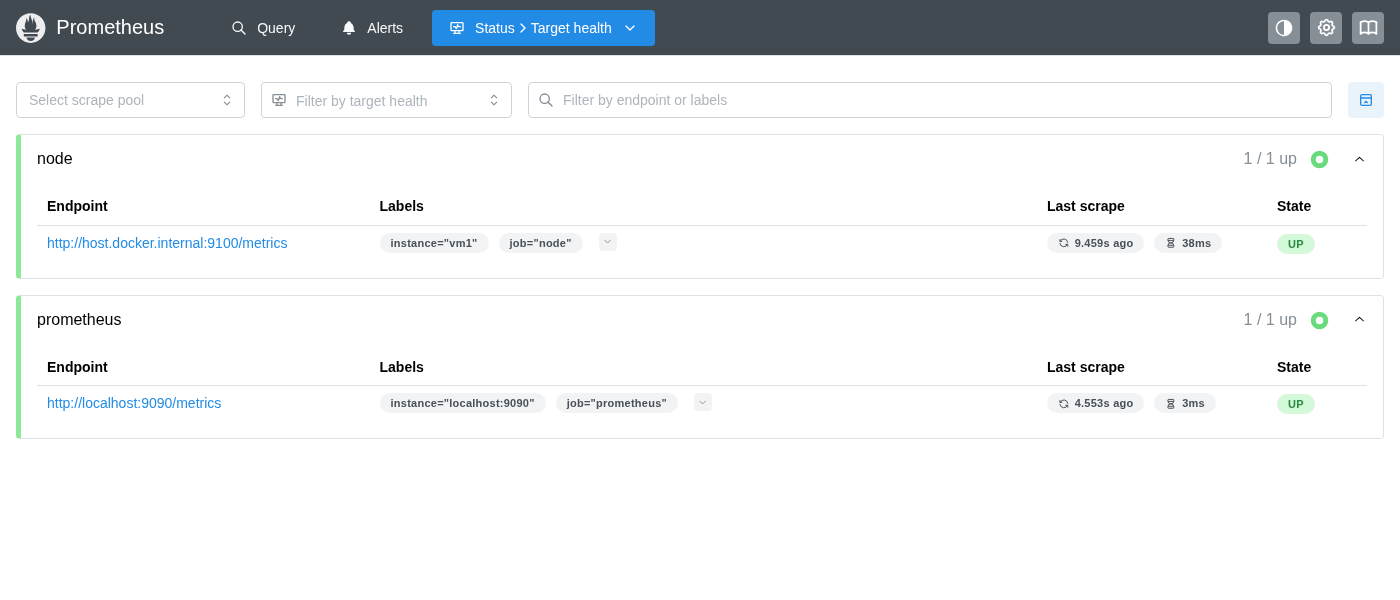

Save & test (внизу)

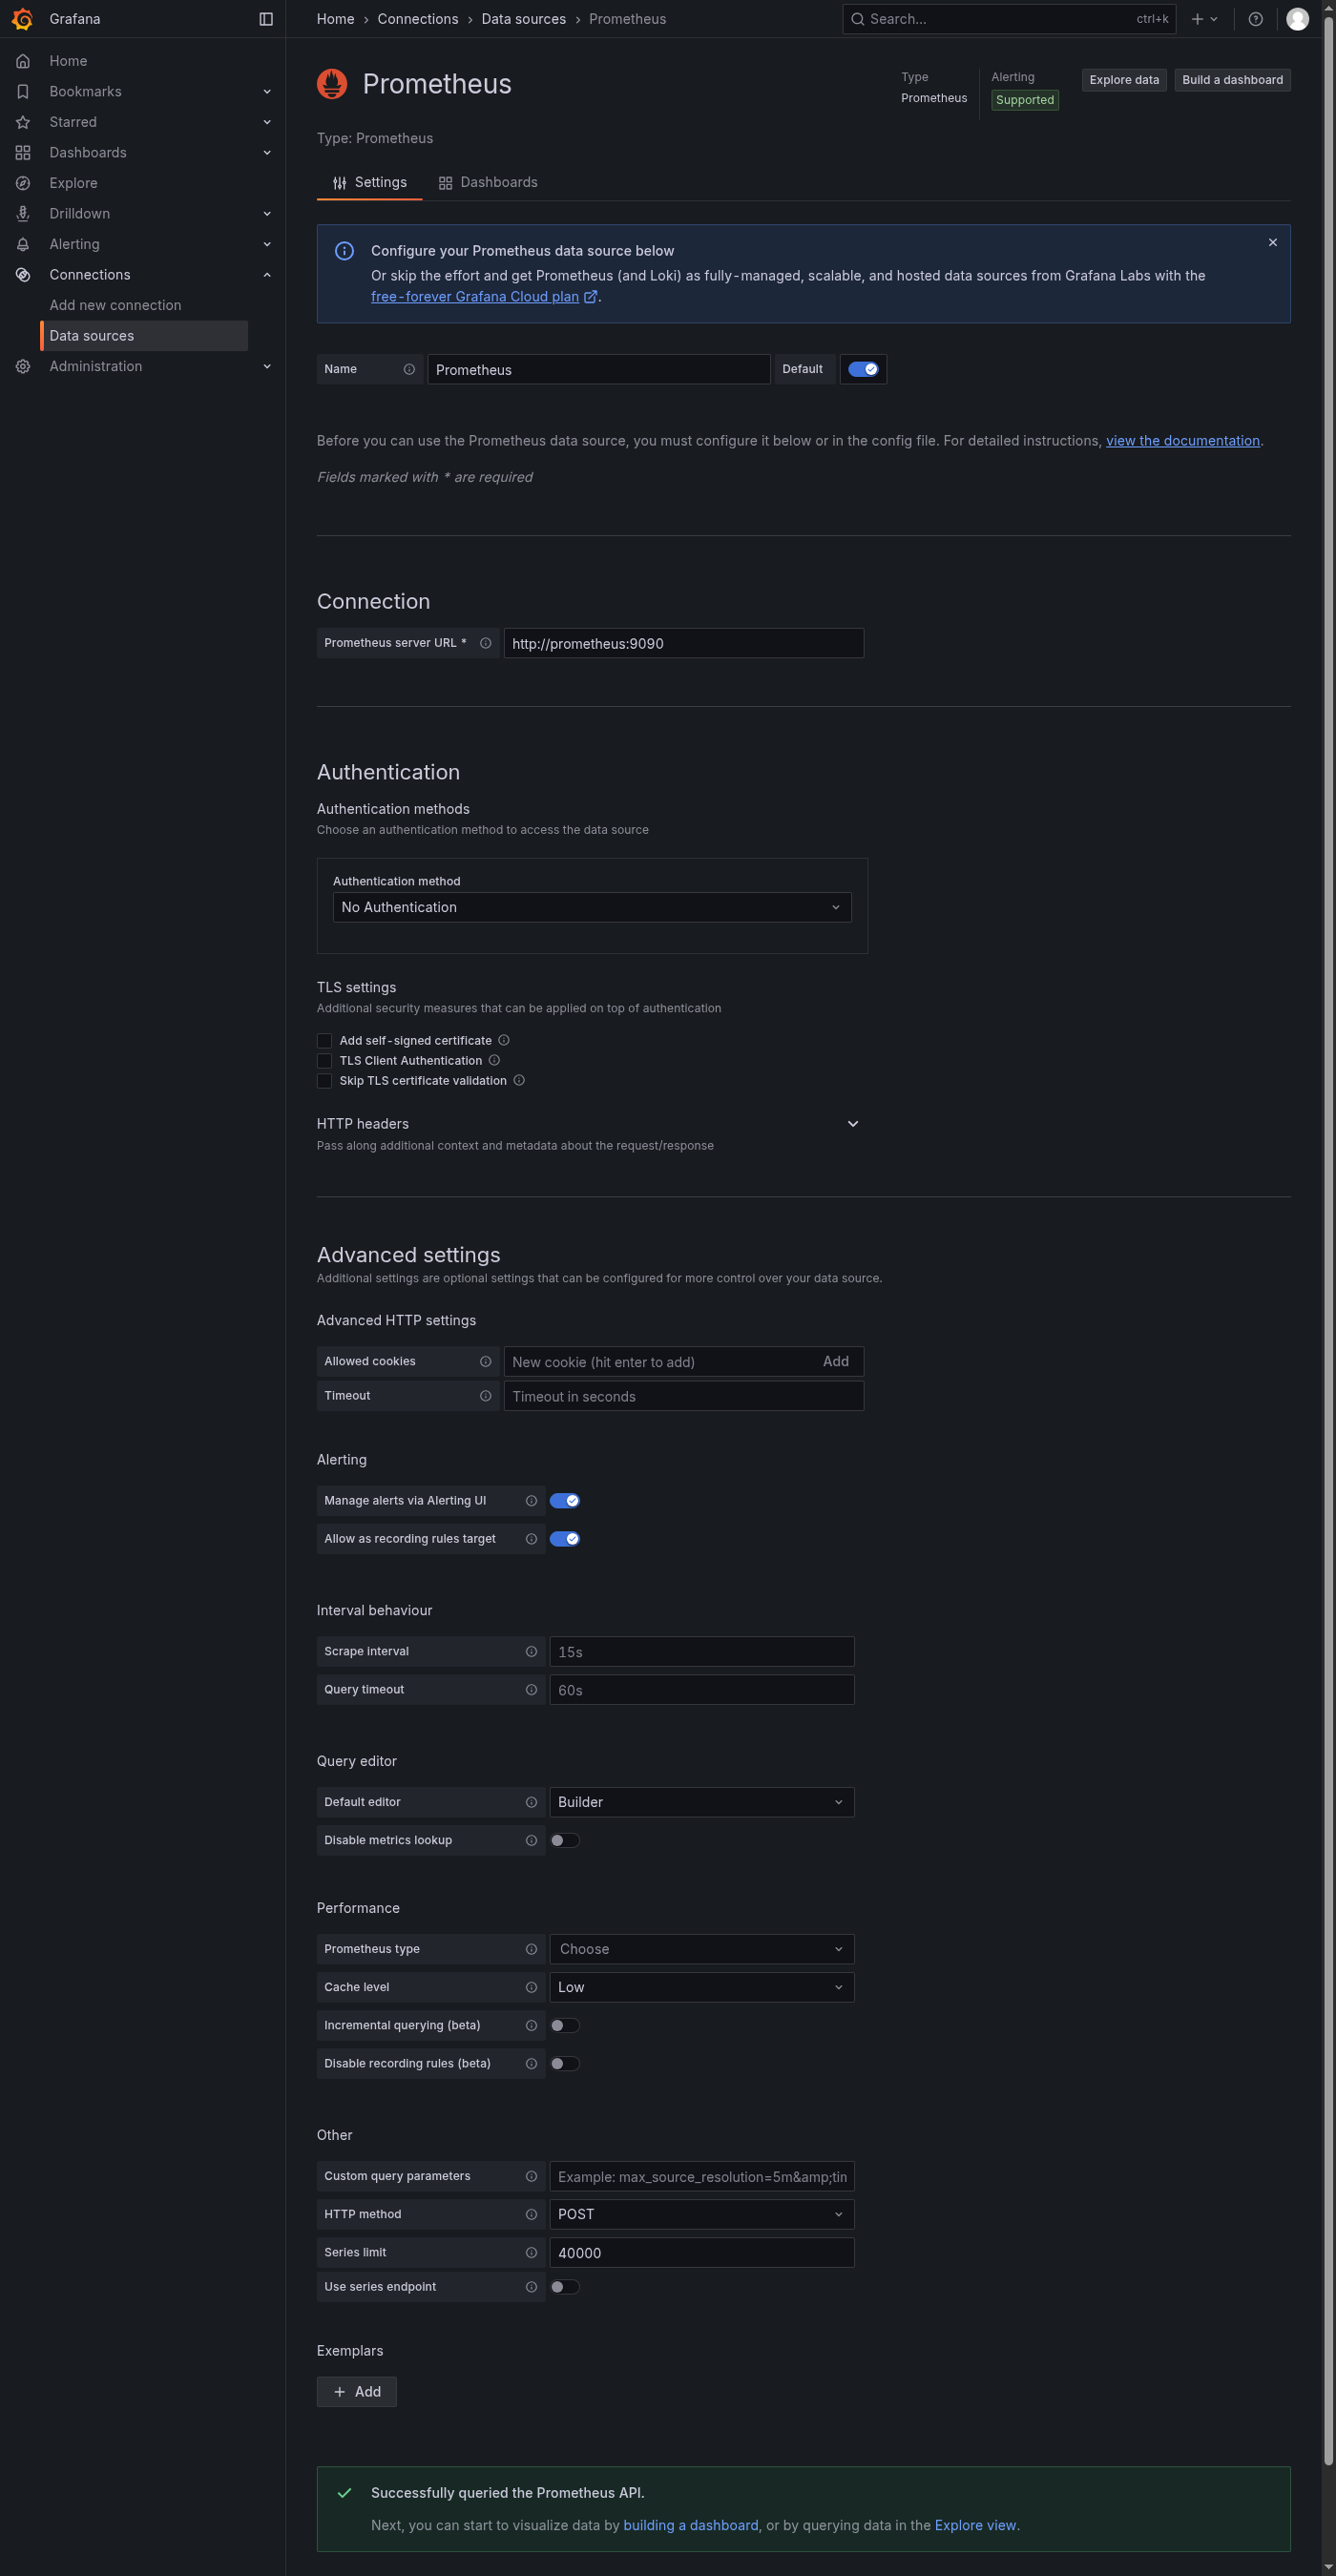

Дашборд. Всплески - это сборка образов

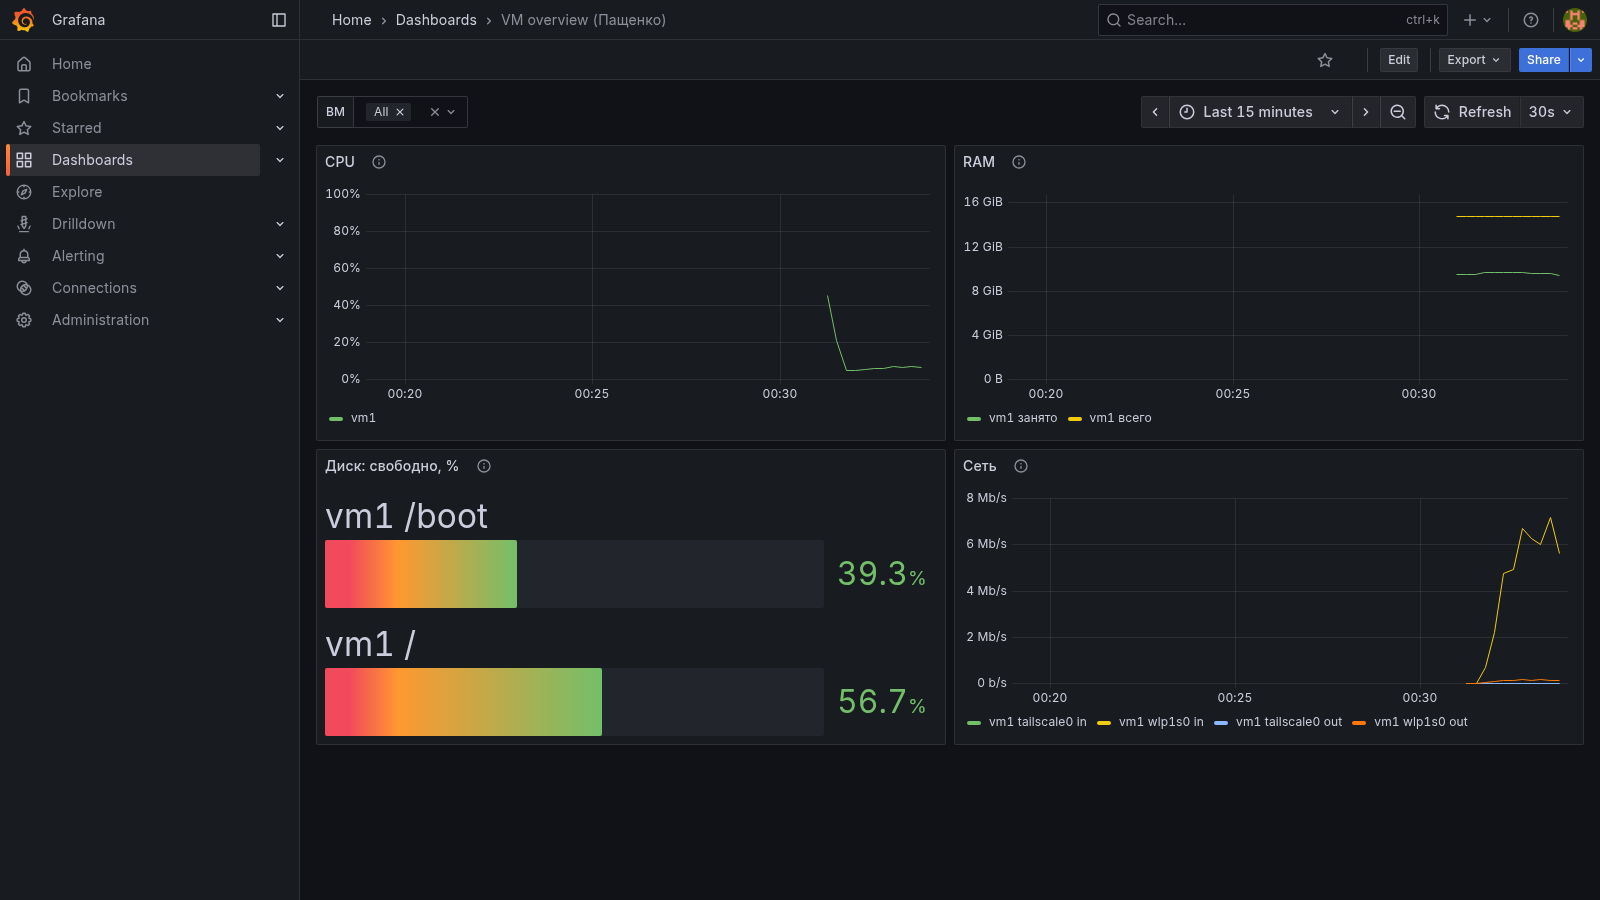